# 3. Does the NM lead or follow spontaneous movement?

Only the second before the stimulus is used: the one stretch of the ±1 s snippets without task events. Within it:
- **Events:** starts and stops of paw, whisking and wheel movement, and lick onsets (z-scored log vigor: quiet for ≥ 200 ms then above threshold, or the reverse for stops). Events must fall 0.7–0.27 s before the stimulus, so the NM window around them (−0.3 to +0.27 s) ends before the stimulus.
- **Correction:** the NM at each event minus the NM at the same time-to-stimulus in trials without that event. This removes the pre-stimulus ramp.
- **Lead or follow:** the NM change *before* the event (−0.2 to −0.07 s, relative to −0.3 to −0.23 s) and *after* it (0.1 to 0.23 s), mice as the unit. *First deviation* is the earliest lag from which the across-mice t-test stays at p < 0.05 for 3 samples (100 ms).

**Caveat on timing:** the fluorescent sensors respond with a delay (tens to a few hundred ms). An NM that changes with or shortly after the movement may really be simultaneous. A change *before* the movement is the strong evidence, since sensor delay works against it.

Functions and cache: `movement_onsets.py`.

In [1]:
import sys, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_1samp

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'nm_syllables.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'neuromodulators' / 'behavioural_states'))
import movement_onsets as mo
warnings.filterwarnings('ignore')
pd.set_option('display.width', 220)

if not (mo.OUT / f'onset_curves_{mo.ns.RUN}.pkl').exists():
    mo.run()
T = mo.load()
NM_ORDER = ['DR-5HT', 'VTA-DA', 'SNc-DA', 'LC-NE', 'NBM-ACh']
NM_COLORS = dict(zip(NM_ORDER, ['#CC79A7', '#E69F00', '#D55E00', '#0072B2', '#009E73']))
M = mo.mouse_curves(T)
own = pd.concat([mo.mouse_curves(T[T['signal'].str.startswith(k)], f'v {k}').rename(columns={f'v {k}': 'own'})
                 for k in mo.SIGNALS])
M = M.merge(own[['target_NM', 'signal', 'subject', 'own']], on=['target_NM', 'signal', 'subject'])

def first_deviation(curves, run=3, alpha=0.05):
    p = ttest_1samp(curves - mo.window_mean(curves, -0.3, -0.23)[:, None], 0).pvalue
    for i in range(len(p) - run + 1):
        if mo.LAGS[i] > -0.23 and (p[i:i + run] < alpha).all():
            return mo.LAGS[i]
    return np.nan

rows = []
for (nm, ev), g in M.groupby(['target_NM', 'signal']):
    C = np.stack(g['NM'])
    base = mo.window_mean(C, -0.3, -0.23)
    pre, post = mo.window_mean(C, -0.2, -0.07) - base, mo.window_mean(C, 0.1, 0.23) - base
    ok = len(g) > 2
    rows.append({'NM': nm, 'event': ev, 'mice': len(g), 'events': g['n'].sum(),
                 'Δ before': pre.mean(), 'p before': ttest_1samp(pre, 0).pvalue if ok else np.nan,
                 'Δ after': post.mean(), 'p after': ttest_1samp(post, 0).pvalue if ok else np.nan,
                 'first deviation (s)': first_deviation(C) if ok else np.nan})
R = pd.DataFrame(rows)
R = R[R['mice'] >= 4]
R.pivot_table(index='event', columns='NM', values=['Δ after', 'p after'])[[(v, nm) for v in ['Δ after', 'p after'] for nm in NM_ORDER]].round(3)

Δ after                              p after                             
NM            DR-5HT VTA-DA SNc-DA  LC-NE NBM-ACh  DR-5HT VTA-DA SNc-DA  LC-NE NBM-ACh
event                                                                                 
lick on        0.219 -0.118 -0.093  0.271   0.002   0.031  0.014  0.427  0.062   0.970
paw off       -0.172  0.169  0.216 -0.168  -0.094   0.001  0.008  0.003  0.016   0.074
paw on         0.468 -0.009    NaN    NaN   0.230   0.054  0.961    NaN    NaN   0.266
wheel off     -0.044  0.159  0.302 -0.158  -0.129   0.278  0.046  0.008  0.010   0.039
wheel on       0.267 -0.027 -0.300  0.362   0.229   0.005  0.816  0.225  0.142   0.077
whisking off  -0.159  0.145  0.216 -0.090  -0.098   0.015  0.033  0.035  0.126   0.027
whisking on    0.392 -0.001 -0.300  0.278   0.282   0.030  0.993  0.091  0.116   0.014

## Onset-locked NM

Mean ± sem across mice (z-scored photometry, corrected). Grey: the movement itself (z, right axis). Only events with ≥ 4 mice per NM. Stops are more common than starts here, because the mouse settles before the stimulus.

mice  events  Δ before  p before  Δ after  p after  first deviation (s)
event        NM                                                                              
lick on      DR-5HT      7    1619     0.111     0.049    0.219    0.031               -0.133
             LC-NE       7     429     0.101     0.093    0.271    0.062                  NaN
             NBM-ACh     5     825     0.038     0.343    0.002    0.970                  NaN
             SNc-DA      4    1292    -0.123     0.313   -0.093    0.427                  NaN
             VTA-DA      5    1521     0.001     0.981   -0.118    0.014                0.100
paw off      DR-5HT      9   22670    -0.020     0.175   -0.172    0.001               -0.033
             LC-NE       8   14974    -0.002     0.920   -0.168    0.016                0.133
             NBM-ACh     7   12179    -0.003     0.918   -0.094    0.074                  NaN
             SNc-DA      6    7865     0.041     0.198    0.216    0.003               -0.067
             VTA-DA      7   20013     0.032     0.127    0.169    0.008               -0.100
paw on       DR-5HT      5     259     0.055     0.635    0.468    0.054                0.067
             NBM-ACh     4     164     0.037     0.657    0.230    0.266                  NaN
             VTA-DA      4     484     0.094     0.199   -0.009    0.961                  NaN
wheel off    DR-5HT      9   37458     0.033     0.144   -0.044    0.278                  NaN
             LC-NE       8   25524    -0.022     0.327   -0.158    0.010                0.100
             NBM-ACh     7   21099    -0.022     0.063   -0.129    0.039                0.100
             SNc-DA      6   13864     0.026     0.468    0.302    0.008                0.000
             VTA-DA      7   34741    -0.006     0.751    0.159    0.046                0.133
wheel on     DR-5HT      9    1787     0.011     0.698    0.267    0.005               -0.033
             LC-NE       7     558     0.021     0.661    0.362    0.142                  NaN
             NBM-ACh     6    1280    -0.005     0.724    0.229    0.077                  NaN
             SNc-DA      4     509     0.005     0.546   -0.300    0.225                  NaN
             VTA-DA      7    2334     0.032     0.267   -0.027    0.816                  NaN
whisking off DR-5HT      9   21403     0.000     0.999   -0.159    0.015               -0.033
             LC-NE       8   17558    -0.009     0.714   -0.090    0.126                  NaN
             NBM-ACh     7    8255    -0.004     0.897   -0.098    0.027                0.067
             SNc-DA      6    6708     0.042     0.013    0.216    0.035               -0.167
             VTA-DA      7   20596     0.039     0.038    0.145    0.033               -0.100
whisking on  DR-5HT      8    1489    -0.049     0.107    0.392    0.030                0.100
             LC-NE       7    1137    -0.022     0.379    0.278    0.116                  NaN
             NBM-ACh     6     289     0.091     0.129    0.282    0.014                0.100
             SNc-DA      4     294     0.051     0.558   -0.300    0.091                  NaN
             VTA-DA      6    2886     0.028     0.062   -0.001    0.993                  NaN

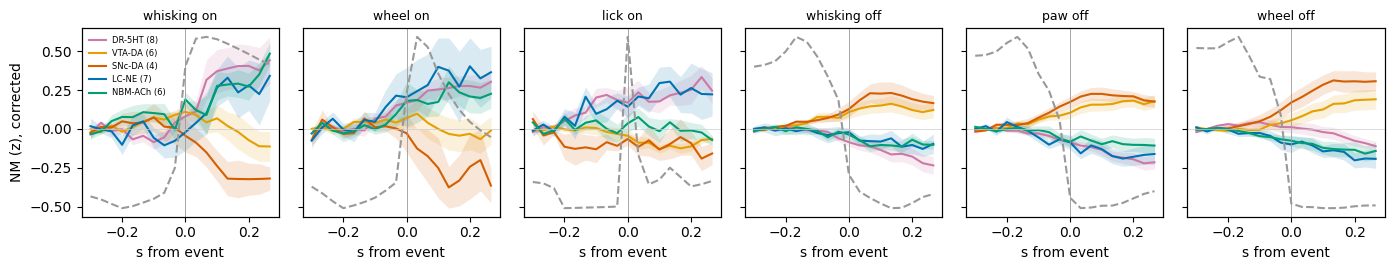

In [2]:
EVS = ['whisking on', 'wheel on', 'lick on', 'whisking off', 'paw off', 'wheel off']
fig, axes = plt.subplots(1, len(EVS), figsize=(14, 2.8), sharey=True)
for ax, ev in zip(axes, EVS):
    g = M[M['signal'] == ev]
    for nm in NM_ORDER:
        c = g[g['target_NM'] == nm]
        if len(c) < 4:
            continue
        C = np.stack(c['NM']); C = C - mo.window_mean(C, -0.3, -0.23)[:, None]
        ax.plot(mo.LAGS, C.mean(0), color=NM_COLORS[nm], label=f'{nm} ({len(c)})')
        ax.fill_between(mo.LAGS, C.mean(0) - C.std(0) / np.sqrt(len(c)), C.mean(0) + C.std(0) / np.sqrt(len(c)),
                        color=NM_COLORS[nm], alpha=0.15, lw=0)
    a2 = ax.twinx()
    a2.plot(mo.LAGS, np.stack(g['own']).mean(0), color='0.6', ls='--'); a2.set_yticks([])
    ax.axvline(0, c='0.6', lw=0.6); ax.axhline(0, c='0.8', lw=0.5)
    ax.set_title(ev, fontsize=9); ax.set_xlabel('s from event')
axes[0].set_ylabel('NM (z), corrected')
axes[0].legend(fontsize=6, frameon=False)
fig.tight_layout()
R.set_index(['event', 'NM']).sort_index().round(3)

## Reading

- **DA mirrors the other NMs.**
  - When the mouse **stops** (paw, whisking or wheel), DA rises: SNc +0.2–0.3 z, VTA +0.15–0.17, p < 0.05 for all three movements. 5HT, NE and ACh fall (−0.1 to −0.17).
  - When it **starts** whisking or turning the wheel, 5HT, NE and ACh rise (+0.2–0.4; significant for 5HT wheel and whisking and ACh whisking). SNc-DA falls, though in only 4 mice and not significant.
  - So before the stimulus, DA tracks *stillness* and the others track *movement*.
- **Timing: with the movement, not clearly ahead of it.**
  - At stops, DA starts rising 100–170 ms before the stop crossing. But the movement itself starts slowing ~170 ms before the crossing (grey), so DA rises *as the mouse decelerates*.
  - At starts, 5HT, NE and ACh deviate 0–100 ms after the onset.
  - Sensor delays push NM signals later, so equal timing in fluorescence means the NM changes at least as early as the movement. This is not a lead that rules out the reverse direction, though.
- **The one possible lead:** 5HT rises ~130 ms before lick onsets (p = 0.049). Lick onsets are usually preceded by approach movements, so this is weak.

**Caveats.**
- Starts are rare in this window: the mouse is settling before the stimulus, so stops outnumber starts about 10:1.
- Stops of paw, whisking and wheel happen together, so the three stop panels are largely the same events.
- Only the ±1 s snippets are available. Continuous photometry would give many more spontaneous events, in the ITI too, and allow a proper cross-correlation or encoding-model lag analysis.